# Linear Regression Objective 2.1: 

### Task

Building linear regression model that evaluate prediciton the goal difference between two opposing teams across 104 FIFA World Cup Matches using eigh pre-match explanator variables.

### Outcome

Goal Difference = Goals scored by Team A - Goals scored by Team B

The dataset sourced from the FIFA official statistics platform, The Stats Don't Lie, and FBref. all the explanatory variables are created only for information available before the focal match and rolling statistics use earlier tournament matches only to prevent target leakage.

## This code file contains:

data validation, EDA, inferential testing, correlation, baseline OLS, systematic model experimentation, ridge comparison, residual diagnostics, influece analysis, senstitive checks, visualisation, and final recommendation.

In [54]:
# importing the library

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor


from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score



In [55]:
df = pd.read_csv('Objective_2_1_Dataset.csv')
df.head(10)

,match_id,stage,team_A,team_B,goals_A,goals_B,goal_difference,X1_ppg_diff,X2_avg_goals_for_diff,X3_avg_goals_against_diff,X4_win_rate_diff,X5_clean_sheet_rate_diff,X6_scored_2plus_rate_diff,X7_previous_goal_margin_diff,X8_host_advantage_diff
0,1,Group A,Mexico,South Africa,2,0,2,0.0,0.0,0.0,0.0,0.0,0.0,0,1
1,2,Group A,South Korea,Czechia,2,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0,0
2,3,Group B,Canada,Bosnia and Herzegovina,1,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0,1
3,4,Group D,United States,Paraguay,4,1,3,0.0,0.0,0.0,0.0,0.0,0.0,0,1
4,5,Group B,Qatar,Switzerland,1,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0,0
5,6,Group C,Brazil,Morocco,1,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0,0
6,7,Group C,Haiti,Scotland,0,1,-1,0.0,0.0,0.0,0.0,0.0,0.0,0,0
7,8,Group D,Australia,Türkiye,2,0,2,0.0,0.0,0.0,0.0,0.0,0.0,0,0
8,9,Group E,Germany,Curaçao,7,1,6,0.0,0.0,0.0,0.0,0.0,0.0,0,0
9,10,Group F,Netherlands,Japan,2,2,0,0.0,0.0,0.0,0.0,0.0,0.0,0,0


In [56]:
# reading the data type
df.dtypes

match_id                          int64
stage                               str
team_A                              str
team_B                              str
goals_A                           int64
goals_B                           int64
goal_difference                   int64
X1_ppg_diff                     float64
X2_avg_goals_for_diff           float64
X3_avg_goals_against_diff       float64
X4_win_rate_diff                float64
X5_clean_sheet_rate_diff        float64
X6_scored_2plus_rate_diff       float64
X7_previous_goal_margin_diff      int64
X8_host_advantage_diff            int64
dtype: object

### Dataset Specification:
- 104 rows, one per actual World Cup 2026 match;
- exactly 8 explanatory variables;
- target = goal_difference;
- explanatory variables are based only on information available before the match.

In [57]:
predictors = [
    "X1_ppg_diff",
    "X2_avg_goals_for_diff",
    "X3_avg_goals_against_diff",
    "X4_win_rate_diff",
    "X5_clean_sheet_rate_diff",
    "X6_scored_2plus_rate_diff",
    "X7_previous_goal_margin_diff",
    "X8_host_advantage_diff",
]
target = "goal_difference"

assert len(df) == 104
assert len(predictors) == 8
assert df[predictors + [target]].isna().sum().sum() == 0
assert (df["goal_difference"] == df["goals_A"] - df["goals_B"]).all()

quality_check = pd.DataFrame({
    "Check": [
        "Match rows",
        "Explanatory variables",
        "Missing predictor/target values",
        "Target calculation errors",
        "Constant predictors"
    ],
    "Required": [104, 8, 0, 0, 0],
    "Observed": [
        len(df),
        len(predictors),
        int(df[predictors + [target]].isna().sum().sum()),
        int((df["goal_difference"] != df["goals_A"] - df["goals_B"]).sum()),
        int(sum(df[c].nunique() <= 1 for c in predictors))
    ]
})
quality_check["Status"] = np.where(
    quality_check["Required"] == quality_check["Observed"], "PASS", "CHECK"
)
quality_check

,Check,Required,Observed,Status
0,Match rows,104,104,PASS
1,Explanatory variables,8,8,PASS
2,Missing predictor/target values,0,0,PASS
3,Target calculation errors,0,0,PASS
4,Constant predictors,0,0,PASS


### Exploratory data analysis (EDA)
The goal is to identify:
- central tendency and spread,
- outcome-group differences,
- distribution shape and potential outliers,
- correlations and multicollinearity,
- issues that justify model variations.

In [58]:
eda_cols = predictors + [target]

summary = pd.DataFrame({
    "mean": df[eda_cols].mean(),
    "median": df[eda_cols].median(),
    "std": df[eda_cols].std(),
    "IQR": df[eda_cols].quantile(0.75) - df[eda_cols].quantile(0.25),
    "min": df[eda_cols].min(),
    "max": df[eda_cols].max(),
    "skew": df[eda_cols].skew()
}).round(4)

summary

,mean,median,std,IQR,min,max,skew
X1_ppg_diff,0.0782,0.0,1.0086,0.5000,-3.0,3.0,-0.3319
X2_avg_goals_for_diff,0.0661,0.0,1.3337,1.3083,-4.5,6.0,0.3195
X3_avg_goals_against_diff,-0.1759,0.0,1.2709,0.8959,-6.0,3.0,-0.7672
X4_win_rate_diff,0.0345,0.0,0.3870,0.0000,-1.0,1.0,-0.1507
X5_clean_sheet_rate_diff,0.0172,0.0,0.4423,0.0500,-1.0,1.0,-0.1829
X6_scored_2plus_rate_diff,0.0265,0.0,0.4546,0.0000,-1.0,1.0,-0.1623
X7_previous_goal_margin_diff,0.3558,0.0,2.2851,1.0000,-8.0,8.0,-0.0412
X8_host_advantage_diff,0.0673,0.0,0.3756,0.0000,-1.0,1.0,0.7539
goal_difference,0.4808,0.0,2.0240,3.0000,-4.0,6.0,0.2577


### The outcome group descriptive analysis
Goal difference is grouped into three difference categories:
- Team A loss (goal_difference < 0)
- Draw (goal_difference = 0)
- Team A win (goal_difference > 0)

In [61]:
df["outcome_group"] = pd.cut(
    df[target],
    bins=[-np.inf, -0.5, 0.5, np.inf],
    labels=["Team A loss", "Draw", "Team A win"]
)

group_summary = (
    df.groupby("outcome_group", observed=True)[predictors]
      .agg(["mean", "median", "std"])
      .round(3)
)
group_summary

X1_ppg_diff               X2_avg_goals_for_diff                \
                     mean median    std                  mean median    std   
outcome_group                                                                 
Team A loss        -0.430    0.0  1.005                -0.489 -0.125  1.082   
Draw                0.139    0.0  0.336                 0.292  0.000  1.029   
Team A win          0.354    0.0  1.118                 0.291  0.000  1.511   

              X3_avg_goals_against_diff               X4_win_rate_diff  ...  \
                                   mean median    std             mean  ...   
outcome_group                                                           ...   
Team A loss                       0.316  0.000  1.432           -0.112  ...   
Draw                             -0.229  0.000  1.455            0.056  ...   
Team A win                       -0.445 -0.292  0.982            0.112  ...   

              X5_clean_sheet_rate_diff X6_scored_2plus_rate_diff         \
                                   std                      mean median   
outcome_group                                                             
Team A loss                      0.462                    -0.167    0.0   
Draw                             0.405                     0.097    0.0   
Team A win                       0.430                     0.108    0.0   

                     X7_previous_goal_margin_diff                \
                 std                         mean median    std   
outcome_group                                                     
Team A loss    0.483                       -0.667    0.0  2.426   
Draw           0.399                        0.958    0.0  2.331   
Team A win     0.435                        0.680    0.5  2.004   

              X8_host_advantage_diff                
                                mean median    std  
outcome_group                                       
Team A loss                    0.033    0.0  0.414  
Draw                           0.042    0.0  0.204  
Team A win                     0.100    0.0  0.416  

[3 rows x 24 columns]

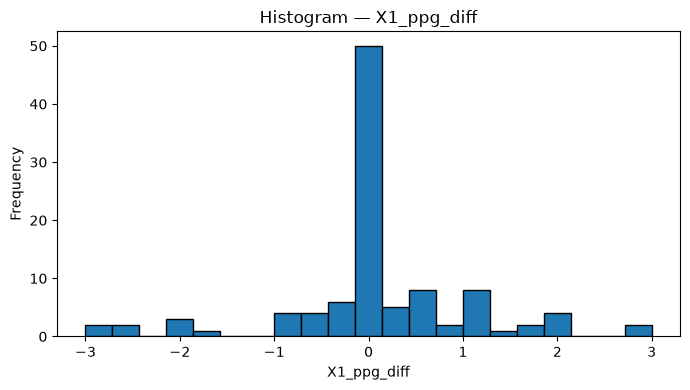

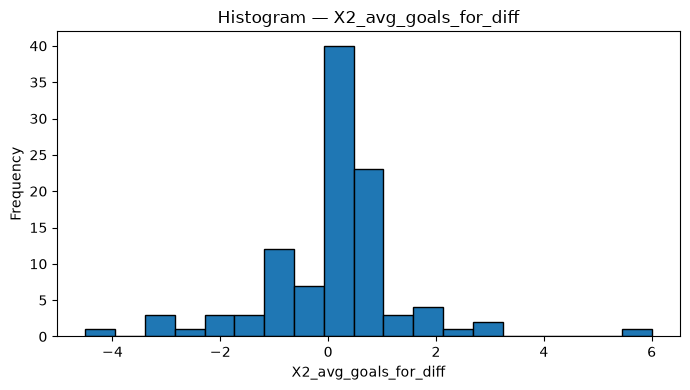

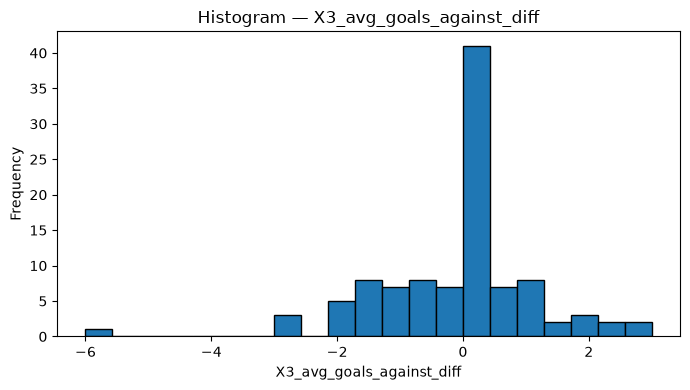

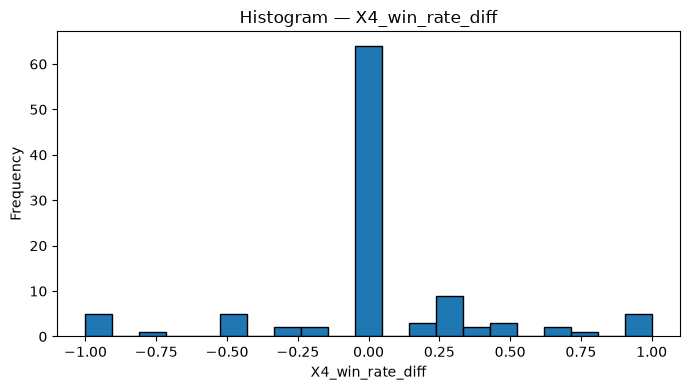

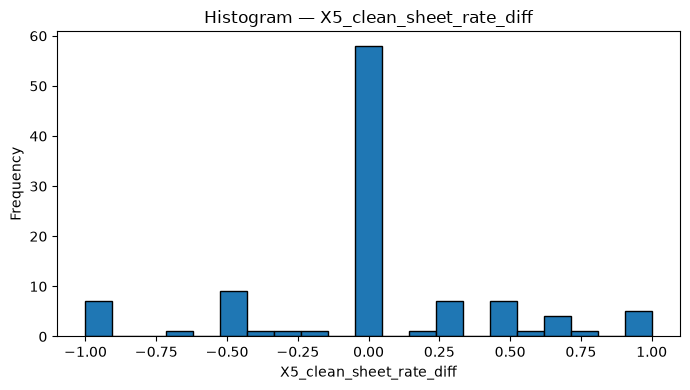

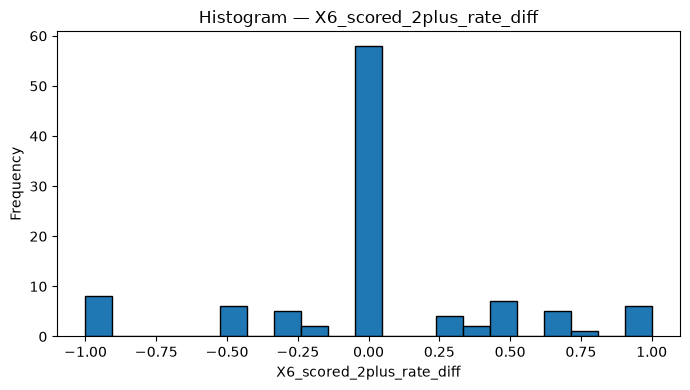

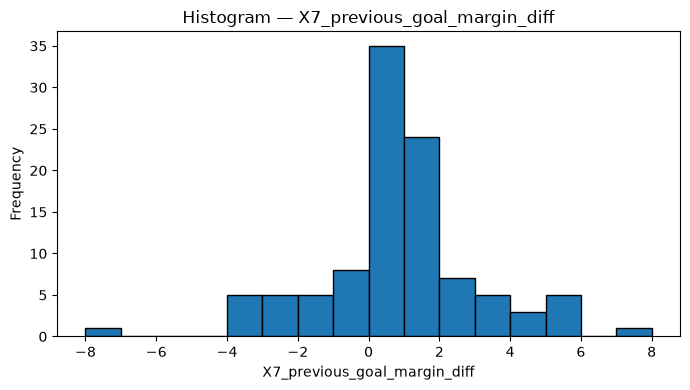

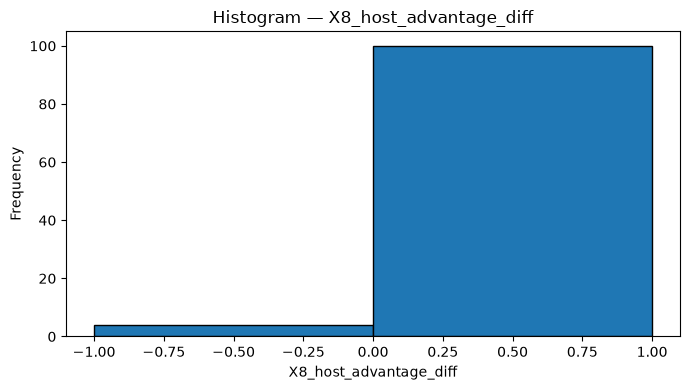

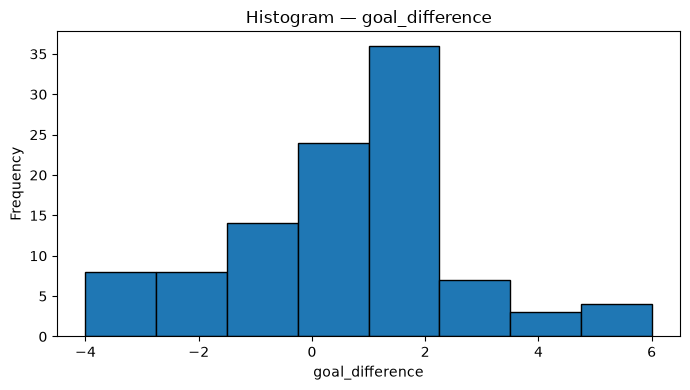

/tmp/ipykernel_5639/1746230033.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col], vert=False)


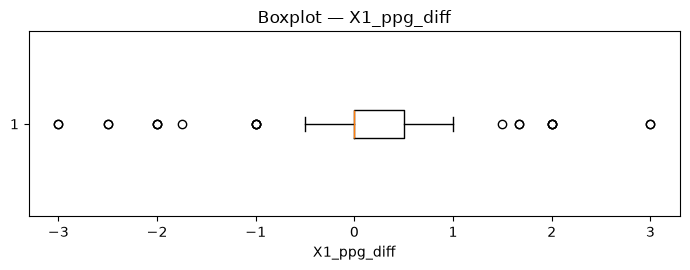

/tmp/ipykernel_5639/1746230033.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col], vert=False)


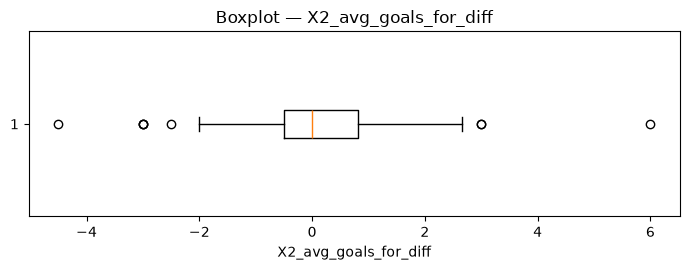

/tmp/ipykernel_5639/1746230033.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col], vert=False)


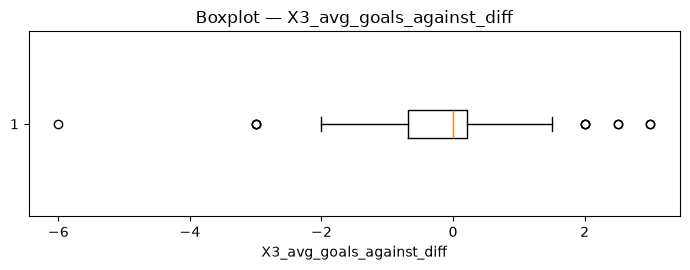

/tmp/ipykernel_5639/1746230033.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col], vert=False)


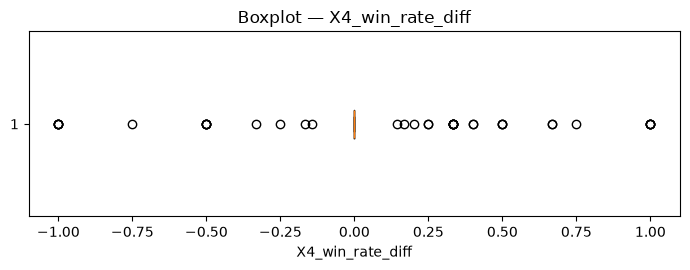

/tmp/ipykernel_5639/1746230033.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col], vert=False)


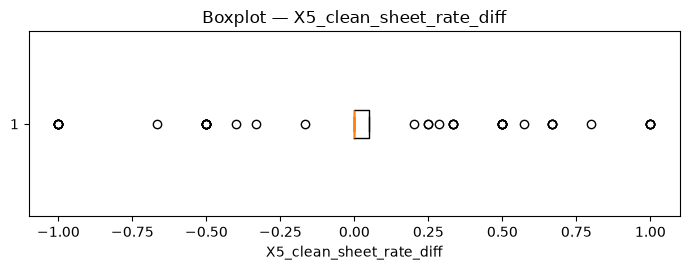

/tmp/ipykernel_5639/1746230033.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col], vert=False)


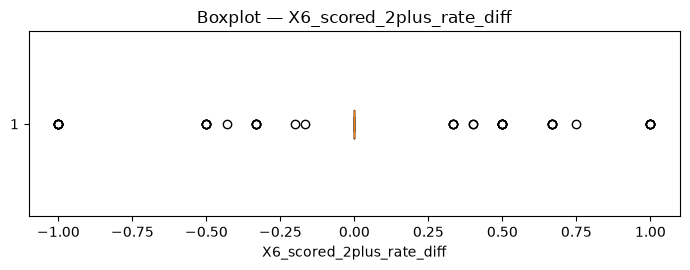

/tmp/ipykernel_5639/1746230033.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col], vert=False)


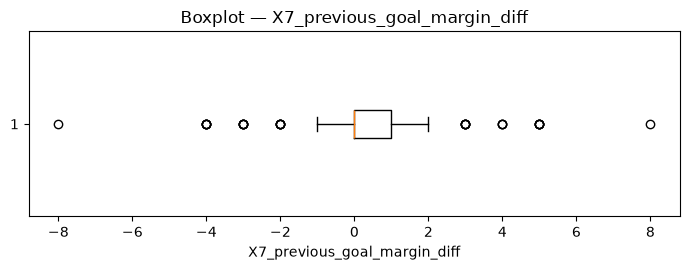

/tmp/ipykernel_5639/1746230033.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col], vert=False)


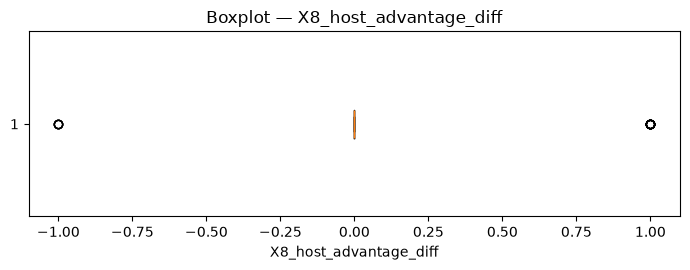

/tmp/ipykernel_5639/1746230033.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col], vert=False)


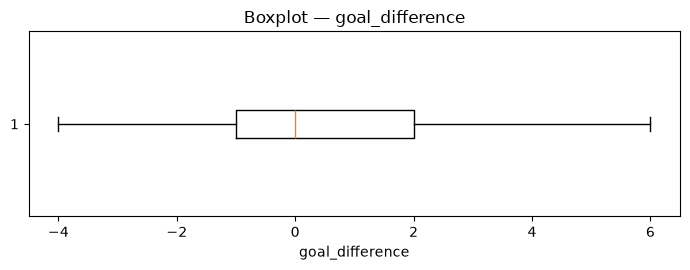

In [62]:
for col in eda_cols:
    plt.figure(figsize=(7, 4))
    plt.hist(df[col], bins="auto", edgecolor="black")
    plt.title(f"Histogram — {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

for col in eda_cols:
    plt.figure(figsize=(7, 2.8))
    plt.boxplot(df[col], vert=False)
    plt.title(f"Boxplot — {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

In [63]:
outlier_records = []

for col in eda_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flagged = df[(df[col] < low) | (df[col] > high)]
    outlier_records.append({
        "variable": col,
        "lower_fence": round(low, 4),
        "upper_fence": round(high, 4),
        "n_flagged": len(flagged)
    })

outlier_table = pd.DataFrame(outlier_records)
outlier_table

,variable,lower_fence,upper_fence,n_flagged
0,X1_ppg_diff,-0.7500,1.2500,21
1,X2_avg_goals_for_diff,-2.4625,2.7708,8
2,X3_avg_goals_against_diff,-2.0313,1.5522,11
3,X4_win_rate_diff,0.0000,0.0000,40
4,X5_clean_sheet_rate_diff,-0.0750,0.1250,46
5,X6_scored_2plus_rate_diff,0.0000,0.0000,46
6,X7_previous_goal_margin_diff,-1.5000,2.5000,30
7,X8_host_advantage_diff,0.0000,0.0000,15
8,goal_difference,-5.5000,6.5000,0


### Inferential foundation (Host advantage)
A Welch t-test compares goal difference for matches where Team A has host advantage versus neutral/non-Team-A-host cases. (the descriptive inferential checking)

In [64]:
host_A = df.loc[df["X8_host_advantage_diff"] == 1, target]
neutral = df.loc[df["X8_host_advantage_diff"] == 0, target]

t_stat, p_value = stats.ttest_ind(host_A, neutral, equal_var=False)

n1, n2 = len(host_A), len(neutral)
s1, s2 = host_A.std(ddof=1), neutral.std(ddof=1)
pooled_sd = np.sqrt(((n1 - 1)*s1**2 + (n2 - 1)*s2**2) / (n1 + n2 - 2))
cohens_d = (host_A.mean() - neutral.mean()) / pooled_sd if pooled_sd > 0 else np.nan

display(pd.DataFrame({
    "group": ["Team A host", "Neutral / no Team A host"],
    "n": [n1, n2],
    "mean_goal_difference": [host_A.mean(), neutral.mean()],
    "std_goal_difference": [s1, s2]
}).round(4))

print(f"Welch t-statistic: {t_stat:.2f}")
print(f"p-value: {p_value:.2f}")
print(f"Cohen's d: {cohens_d:.2f}")

,group,n,mean_goal_difference,std_goal_difference
0,Team A host,11,1.0000,2.6458
1,Neutral / no Team A host,89,0.4607,1.9485


Welch t-statistic: 0.65
p-value: 0.53
Cohen's d: 0.27


### Correlation and multicollinerarity (EDA)
- strong pairwise correlation.
- inflated variance due to multicollinearity (VIF).

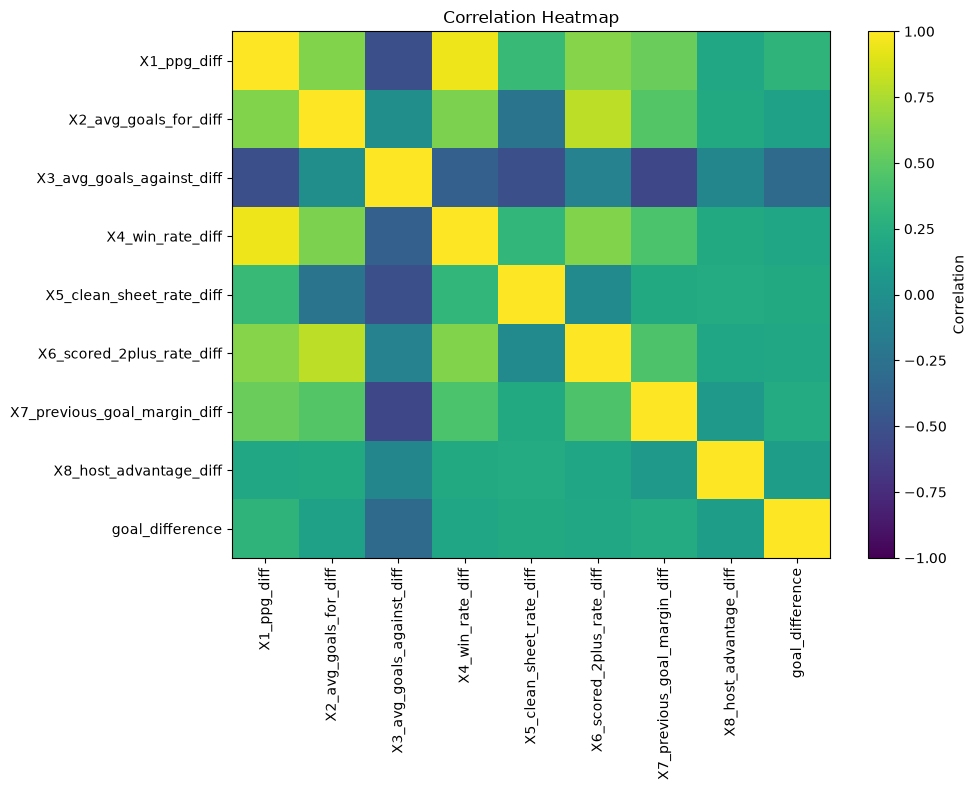

,X1_ppg_diff,X2_avg_goals_for_diff,X3_avg_goals_against_diff,X4_win_rate_diff,X5_clean_sheet_rate_diff,X6_scored_2plus_rate_diff,X7_previous_goal_margin_diff,X8_host_advantage_diff,goal_difference
X1_ppg_diff,1.000,0.619,-0.509,0.951,0.346,0.640,0.542,0.200,0.301
X2_avg_goals_for_diff,0.619,1.000,-0.009,0.604,-0.227,0.802,0.464,0.216,0.144
X3_avg_goals_against_diff,-0.509,-0.009,1.000,-0.391,-0.508,-0.117,-0.566,-0.083,-0.312
X4_win_rate_diff,0.951,0.604,-0.391,1.000,0.321,0.622,0.437,0.218,0.181
X5_clean_sheet_rate_diff,0.346,-0.227,-0.508,0.321,1.000,-0.042,0.211,0.227,0.214
X6_scored_2plus_rate_diff,0.640,0.802,-0.117,0.622,-0.042,1.000,0.439,0.179,0.203
X7_previous_goal_margin_diff,0.542,0.464,-0.566,0.437,0.211,0.439,1.000,0.074,0.233
X8_host_advantage_diff,0.200,0.216,-0.083,0.218,0.227,0.179,0.074,1.000,0.123
goal_difference,0.301,0.144,-0.312,0.181,0.214,0.203,0.233,0.123,1.000


In [65]:
corr = df[predictors + [target]].corr()

plt.figure(figsize=(10, 8))
im = plt.imshow(corr, vmin=-1, vmax=1, aspect="auto")
plt.colorbar(im, label="Correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.index)), corr.index)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

corr.round(3)

In [66]:
X = df[predictors]
y = df[target]

X_vif = sm.add_constant(X)

vif_table = pd.DataFrame({
    "Variable": predictors,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(1, X_vif.shape[1])
    ]
}).sort_values("VIF", ascending=False)

vif_table

,Variable,VIF
0,X1_ppg_diff,16.772235
3,X4_win_rate_diff,12.434362
1,X2_avg_goals_for_diff,5.200644
5,X6_scored_2plus_rate_diff,3.113622
2,X3_avg_goals_against_diff,2.666612
6,X7_previous_goal_margin_diff,2.256079
4,X5_clean_sheet_rate_diff,2.092128
7,X8_host_advantage_diff,1.196061


### Baseline multiple linear regression — Full OLS

In [67]:
full_ols = sm.OLS(y, sm.add_constant(X)).fit()
print(full_ols.summary())

                            OLS Regression Results                            
Dep. Variable:        goal_difference   R-squared:                       0.235
Model:                            OLS   Adj. R-squared:                  0.170
Method:                 Least Squares   F-statistic:                     3.640
Date:                Sun, 11 Oct 2026   Prob (F-statistic):           0.000979
Time:                        09:58:17   Log-Likelihood:                -206.49
No. Observations:                 104   AIC:                             431.0
Df Residuals:                      95   BIC:                             454.8
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const           

### Reduced OLS based on VIF
If the highest VIF is above 5, the highest-VIF predictor is removed for this experimental model.
The original dataset still contains exactly eight explanatory variables as required.

In [68]:
highest_vif_variable = vif_table.iloc[0]["Variable"]
highest_vif_value = vif_table.iloc[0]["VIF"]

if highest_vif_value > 5:
    reduced_predictors = [p for p in predictors if p != highest_vif_variable]
    print(f"Removed {highest_vif_variable}; VIF = {highest_vif_value:.2f}")
else:
    reduced_predictors = predictors.copy()
    print("No VIF above 5; reduced model keeps all predictors.")

X_reduced = df[reduced_predictors]
reduced_ols = sm.OLS(y, sm.add_constant(X_reduced)).fit()

print(reduced_ols.summary())

Removed X1_ppg_diff; VIF = 16.77
                            OLS Regression Results                            
Dep. Variable:        goal_difference   R-squared:                       0.148
Model:                            OLS   Adj. R-squared:                  0.086
Method:                 Least Squares   F-statistic:                     2.388
Date:                Sun, 11 Oct 2026   Prob (F-statistic):             0.0270
Time:                        09:58:20   Log-Likelihood:                -212.05
No. Observations:                 104   AIC:                             440.1
Df Residuals:                      96   BIC:                             461.3
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------

### Model comparison
Four models are compared using the same 5-fold cross-validation:
1. Full OLS
2. Reduced OLS
3. Ridge
4. Lasso

Metrics: R², RMSE, and MAE.

In [69]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "r2": "r2",
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error"
}

models = {
    "Full OLS": (LinearRegression(), X[predictors]),
    "Reduced OLS": (LinearRegression(), X[reduced_predictors]),
    "Ridge": (
        Pipeline([
            ("scale", StandardScaler()),
            ("model", Ridge(alpha=1.0))
        ]),
        X[predictors]
    ),
    "Lasso": (
        Pipeline([
            ("scale", StandardScaler()),
            ("model", Lasso(alpha=0.1, max_iter=10000))
        ]),
        X[predictors]
    )
}

results = []

for name, (model, X_model) in models.items():
    cv = cross_validate(model, X_model, y, cv=kf, scoring=scoring)

    results.append({
        "Model": name,
        "CV_R2": cv["test_r2"].mean(),
        "CV_RMSE": -cv["test_rmse"].mean(),
        "CV_MAE": -cv["test_mae"].mean()
    })

model_comparison = pd.DataFrame(results).sort_values("CV_RMSE")
model_comparison.round(4)

,Model,CV_R2,CV_RMSE,CV_MAE
2,Ridge,-0.0259,1.9975,1.5559
0,Full OLS,-0.0324,2.0025,1.5624
3,Lasso,-0.0379,2.0073,1.5041
1,Reduced OLS,-0.1113,2.0798,1.6012


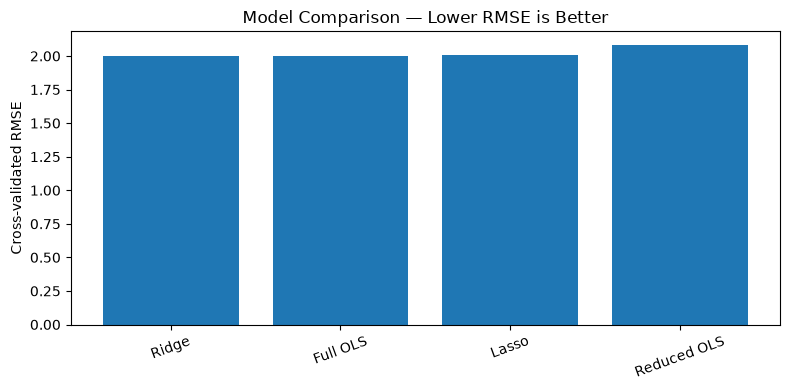

In [70]:
plt.figure(figsize=(8, 4))
plt.bar(model_comparison["Model"], model_comparison["CV_RMSE"])
plt.ylabel("Cross-validated RMSE")
plt.title("Model Comparison — Lower RMSE is Better")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### Residual diagnostics
The horizontal line in the residual plot is intentionally at residual = 0. It is a reference line, not the regression line.

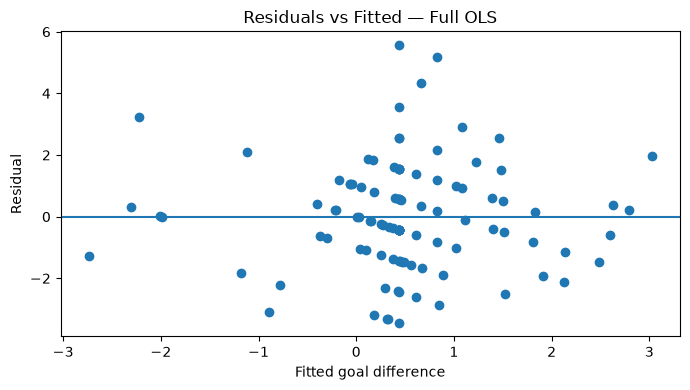

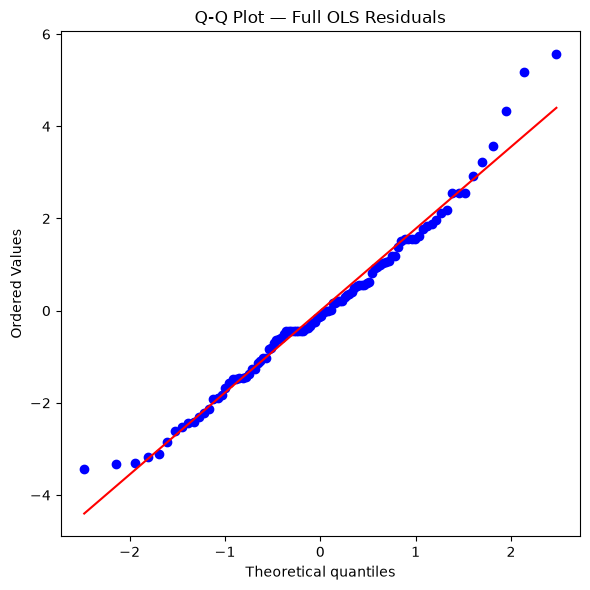

In [71]:
fitted = full_ols.fittedvalues
residuals = full_ols.resid

plt.figure(figsize=(7, 4))
plt.scatter(fitted, residuals)
plt.axhline(0)
plt.xlabel("Fitted goal difference")
plt.ylabel("Residual")
plt.title("Residuals vs Fitted — Full OLS")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 6))
stats.probplot(residuals, dist="norm", plot=plt)
plt.title("Q-Q Plot — Full OLS Residuals")
plt.tight_layout()
plt.show()

### Actual vs predicted (Full OLS)

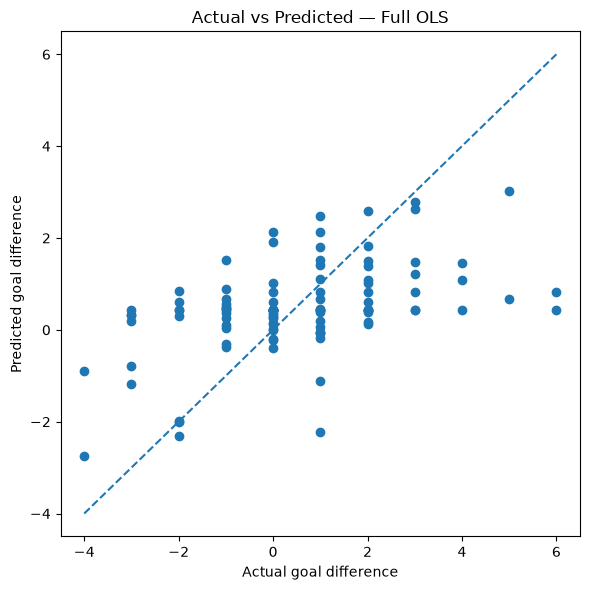

In [72]:
plt.figure(figsize=(6, 6))
plt.scatter(y, fitted)

min_val = min(y.min(), fitted.min())
max_val = max(y.max(), fitted.max())

plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")
plt.xlabel("Actual goal difference")
plt.ylabel("Predicted goal difference")
plt.title("Actual vs Predicted — Full OLS")
plt.tight_layout()
plt.show()

### Final recommendation

In [73]:
best = model_comparison.iloc[0]

print("Recommended model:", best["Model"])
print("CV R²:", round(best["CV_R2"], 3))
print("CV RMSE:", round(best["CV_RMSE"], 3))
print("CV MAE:", round(best["CV_MAE"], 3))

print()
print(
    "The recommendation is based mainly on the lowest cross-validated RMSE, "
    "while also considering simplicity, multicollinearity, and football interpretability."
)

Recommended model: Ridge
CV R²: -0.026
CV RMSE: 1.998
CV MAE: 1.556

The recommendation is based mainly on the lowest cross-validated RMSE, while also considering simplicity, multicollinearity, and football interpretability.


### Limitations
- First tournament matches have limited prior World Cup 2026 form.
- The sample contains only 104 matches.
- Football outcomes contain unpredictable events not represented by the model.
- Linear regression may be too simple for some football relationships.
- Stronger teams appear more often in later tournament rounds.